# Assignment 4, Task 2: Evaluating Reweighing (Kamiran & Calders, 2012)

**Algorithm:** Reweighing (pre-processing), from AIF360 (`aif360.algorithms.preprocessing.Reweighing`).

**Datasets:** Adult (protected attribute `sex`), German Credit (`sex`), COMPAS (`race`).

**Classifier:** logistic regression (scikit-learn), trained with and without instance weights.

**Conventions (state these in the report):**
- Privileged group = value 1 of the protected attribute in AIF360 (Adult: Male; German: male; COMPAS: Caucasian). The favourable label is 1 (Adult: income > 50K; German: good credit; COMPAS: no two-year recidivism).
- `DP_Diff` = P(favourable | unprivileged) - P(favourable | privileged), AIF360's sign convention. 0 is fair, negative means the unprivileged group is disadvantaged. The paper uses the opposite sign (favoured minus deprived).
- `DIR` = P(favourable | unprivileged) / P(favourable | privileged). 1 is fair, and values below 0.8 violate the four-fifths rule.
- `Consistency` = 1 - mean absolute difference between each label and the mean label of its k nearest neighbours (k = 5, standardised features). 1 means similar individuals get similar labels.

## 0. Setup and parameters

In [1]:
import os
import sys
import time
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import sklearn
import aif360
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

from aif360.algorithms.preprocessing import Reweighing
from aif360.datasets import AdultDataset, CompasDataset, GermanDataset
from aif360.metrics import BinaryLabelDatasetMetric

SEEDS = list(range(10))                   
TEST_SIZE = 0.30                          
N_NEIGHBORS = 5                           
CLASSIFIER_PARAMS = dict(max_iter=1000)   
RESULTS_DIR = "results"
os.makedirs(RESULTS_DIR, exist_ok=True)

print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__, "| aif360", getattr(aif360, "__version__", "n/a"))

pip install 'aif360[AdversarialDebiasing]'
pip install 'aif360[AdversarialDebiasing]'
pip install 'aif360[Reductions]'
pip install 'aif360[Reductions]'
pip install 'aif360[inFairness]'
pip install 'aif360[Reductions]'


Python 3.14.4 | numpy 2.5.4 | pandas 2.3.3 | scikit-learn 1.9.1 | aif360 0.6.1


## 1. Datasets

In [2]:
RAW_DIR = os.path.join(os.path.dirname(aif360.__file__), "data", "raw")
UCI = "https://archive.ics.uci.edu/ml/machine-learning-databases"
RAW_FILES = {
    "adult": [f"{UCI}/adult/adult.data", f"{UCI}/adult/adult.test", f"{UCI}/adult/adult.names"],
    "german": [f"{UCI}/statlog/german/german.data", f"{UCI}/statlog/german/german.doc"],
    "compas": ["https://raw.githubusercontent.com/propublica/compas-analysis/master/compas-scores-two-years.csv"],
}


def download_raw_data():
    for folder, urls in RAW_FILES.items():
        os.makedirs(os.path.join(RAW_DIR, folder), exist_ok=True)
        for url in urls:
            target = os.path.join(RAW_DIR, folder, os.path.basename(url))
            if os.path.exists(target):
                continue
            try:
                urllib.request.urlretrieve(url, target)
                print("downloaded", target)
            except Exception as err:
                print(f"COULD NOT DOWNLOAD {url}: {err}\n  -> download it manually into {os.path.dirname(target)}")


download_raw_data()

In [3]:
CONFIG = {
    "Adult":  dict(loader=AdultDataset,  protected="sex"),
    "German": dict(loader=GermanDataset, protected="sex"),
    "COMPAS": dict(loader=CompasDataset, protected="race"),
}

data = {}
for name, cfg in CONFIG.items():
    ds = cfg["loader"]()
    assert cfg["protected"] in ds.protected_attribute_names, f"{cfg['protected']} not in {ds.protected_attribute_names}"
    data[name] = ds
    print(f"{name:7s} rows={ds.features.shape[0]:6d}  features={ds.features.shape[1]:3d}  "
          f"protected={cfg['protected']}  all protected attrs={ds.protected_attribute_names}  "
          f"favourable label={ds.favorable_label}")
print("\nNote: the protected attribute stays in the feature matrix (AIF360 default). Reweighing only changes the training weights.")

Adult   rows= 45222  features= 98  protected=sex  all protected attrs=['race', 'sex']  favourable label=1.0
German  rows=  1000  features= 58  protected=sex  all protected attrs=['sex', 'age']  favourable label=1.0


COMPAS  rows=  6167  features=401  protected=race  all protected attrs=['sex', 'race']  favourable label=0.0

Note: the protected attribute stays in the feature matrix (AIF360 default). Reweighing only changes the training weights.


## 2. Helper functions

In [4]:
def group_spec(prot):
    """Privileged / unprivileged group definition (value 1 = privileged in AIF360)."""
    return [{prot: 1}], [{prot: 0}]


def protected_vector(ds, prot):
    return ds.protected_attributes[:, ds.protected_attribute_names.index(prot)].astype(int)


def consistency(X, y, k=N_NEIGHBORS):
    """1 - mean |y_i - mean label of the k nearest neighbours of i| (the point itself counts as one of the
    k neighbours, as in AIF360). Brute-force search keeps this fast on Adult; it is validated against
    AIF360's own implementation on German in Section 2b."""
    y = np.asarray(y, dtype=float).ravel()
    nn = NearestNeighbors(n_neighbors=k, algorithm="brute", n_jobs=-1).fit(X)
    idx = nn.kneighbors(X, return_distance=False)
    return float(1.0 - np.mean(np.abs(y - y[idx].mean(axis=1))))


def fairness_metrics(ds, prot, X_std):
    """DP_Diff, DIR and consistency of the labels stored in `ds` (original or predicted labels).
    `X_std` is the standardised feature matrix used for the nearest-neighbour search."""
    priv, unpriv = group_spec(prot)
    m = BinaryLabelDatasetMetric(ds, unprivileged_groups=unpriv, privileged_groups=priv)
    try:
        dir_ = float(m.disparate_impact())
    except ZeroDivisionError:
        dir_ = np.nan
    if not np.isfinite(dir_):
        dir_ = np.nan          # privileged positive rate is 0, DIR undefined
    return {
        "DP_Diff": float(m.statistical_parity_difference()),
        "DIR": dir_,
        "Consistency": consistency(X_std, ds.labels.ravel()),
        "Pos_rate_unpriv": float(m.base_rate(privileged=False)),
        "Pos_rate_priv": float(m.base_rate(privileged=True)),
    }


def manual_dp_diff(ds, prot):
    """Independent numpy check of AIF360's statistical parity difference."""
    a = protected_vector(ds, prot)
    fav = (ds.labels.ravel() == ds.favorable_label).astype(float)
    return fav[a == 0].mean() - fav[a == 1].mean()

### 2b. Sanity check: my consistency function vs. AIF360's (German, small enough for the ball-tree version)

In [5]:
ds = data["German"]
prot = CONFIG["German"]["protected"]
priv, unpriv = group_spec(prot)
ds_std = ds.copy(deepcopy=True)
ds_std.features = StandardScaler().fit_transform(ds.features)
ref = float(np.ravel(BinaryLabelDatasetMetric(ds_std, unprivileged_groups=unpriv, privileged_groups=priv)
                     .consistency(n_neighbors=N_NEIGHBORS))[0])
mine = consistency(ds_std.features, ds_std.labels.ravel())
print(f"AIF360 consistency = {ref:.4f} | helper = {mine:.4f} | abs. difference = {abs(ref - mine):.5f}")
if abs(ref - mine) > 0.01:
    print("WARNING: difference above 0.01, check the helper (ties between duplicate rows can cause tiny gaps).")

AIF360 consistency = 0.7402 | helper = 0.7402 | abs. difference = 0.00000


## 3. Fairness of the original labels (before any split, mitigation or classifier)

In [6]:
original = []
for name, ds in data.items():
    prot = CONFIG[name]["protected"]
    X_std = StandardScaler().fit_transform(ds.features)  
    res = fairness_metrics(ds, prot, X_std)
    assert abs(res["DP_Diff"] - manual_dp_diff(ds, prot)) < 1e-9, "DP_Diff differs from the numpy check"
    original.append({"Dataset": name, "Setting": "Original labels (full dataset)", **res})
original = pd.DataFrame(original)
original.to_csv(f"{RESULTS_DIR}/original_labels.csv", index=False)
display(original.set_index(["Dataset", "Setting"]).round(4))

,,DP_Diff,DIR,Consistency,Pos_rate_unpriv,Pos_rate_priv
Dataset,Setting,,,,,
Adult,Original labels (full dataset),-0.1989,0.3635,0.8285,0.1136,0.3125
German,Original labels (full dataset),-0.0748,0.8966,0.7402,0.6484,0.7232
COMPAS,Original labels (full dataset),-0.0971,0.8404,0.6680,0.5114,0.6086


## 4. Pipeline: stratified split, Reweighing on the training data, classifier, evaluation on the test data

In [7]:
def run_seed(name, seed):
    ds = data[name]
    prot = CONFIG[name]["protected"]
    priv, unpriv = group_spec(prot)

    a = protected_vector(ds, prot)
    y = ds.labels.ravel().astype(int)
    idx_tr, idx_te = train_test_split(np.arange(len(y)), test_size=TEST_SIZE,
                                      stratify=2 * y + a, random_state=seed)
    tr, te = ds.subset(idx_tr), ds.subset(idx_te)

    scaler = StandardScaler().fit(tr.features)
    X_tr, X_te = scaler.transform(tr.features), scaler.transform(te.features)
    y_tr, y_te = tr.labels.ravel().astype(int), te.labels.ravel().astype(int)

    rw = Reweighing(unprivileged_groups=unpriv, privileged_groups=priv).fit(tr)
    w_rw = rw.transform(tr).instance_weights

    out = [("True labels (test split)", fairness_metrics(te, prot, X_te))]
    for setting, weights in [("Baseline (no mitigation)", None), ("Reweighing", w_rw)]:
        clf = LogisticRegression(**CLASSIFIER_PARAMS).fit(X_tr, y_tr, sample_weight=weights)
        y_hat = clf.predict(X_te)
        pred = te.copy(deepcopy=True)
        pred.labels = y_hat.reshape(-1, 1).astype(float)
        res = fairness_metrics(pred, prot, X_te)
        res.update({
            "Accuracy": accuracy_score(y_te, y_hat),
            "Balanced_Accuracy": balanced_accuracy_score(y_te, y_hat),
            "F1": f1_score(y_te, y_hat),
        })
        out.append((setting, res))
    return out

In [8]:
records = []
for name in data:
    t0 = time.time()
    for seed in SEEDS:
        for setting, res in run_seed(name, seed):
            records.append({"Dataset": name, "Seed": seed, "Setting": setting, **res})
    print(f"{name}: {len(SEEDS)} splits done in {time.time() - t0:.0f}s")

results = pd.DataFrame(records)
results.to_csv(f"{RESULTS_DIR}/results_per_seed.csv", index=False)

Adult: 10 splits done in 44s
German: 10 splits done in 0s
COMPAS: 10 splits done in 25s


## 5. Results on the held-out test data (mean ± std over the splits)

In [9]:
METRICS = ["DP_Diff", "DIR", "Consistency", "Accuracy", "Balanced_Accuracy", "F1"]
ORDER = ["Original labels (full dataset)", "True labels (test split)", "Baseline (no mitigation)", "Reweighing"]

tables = {}
for name in data:
    rows = []
    o = original[original.Dataset == name].iloc[0]
    rows.append({"Setting": ORDER[0], **{k: f"{o[k]:.3f}" for k in ["DP_Diff", "DIR", "Consistency"]}})
    sub = results[results.Dataset == name]
    for setting in ORDER[1:]:
        s = sub[sub.Setting == setting]
        row = {"Setting": setting}
        for k in METRICS:
            if s[k].notna().any():
                row[k] = f"{s[k].mean():.3f} ± {s[k].std():.3f}"
        rows.append(row)
    tables[name] = pd.DataFrame(rows).set_index("Setting").fillna("-")
    print(f"\n=== {name} | protected attribute: {CONFIG[name]['protected']} | {len(SEEDS)} splits ===")
    display(tables[name])

pd.concat(tables, names=["Dataset"]).to_csv(f"{RESULTS_DIR}/results_summary.csv")


=== Adult | protected attribute: sex | 10 splits ===


,DP_Diff,DIR,Consistency,Accuracy,Balanced_Accuracy,F1
Setting,,,,,,
Original labels (full dataset),-0.199,0.363,0.828,-,-,-
True labels (test split),-0.199 ± 0.000,0.364 ± 0.000,0.824 ± 0.002,-,-,-
Baseline (no mitigation),-0.186 ± 0.005,0.292 ± 0.014,0.944 ± 0.001,0.848 ± 0.003,0.766 ± 0.004,0.663 ± 0.007
Reweighing,-0.087 ± 0.006,0.599 ± 0.019,0.945 ± 0.001,0.842 ± 0.003,0.748 ± 0.005,0.638 ± 0.007



=== German | protected attribute: sex | 10 splits ===


,DP_Diff,DIR,Consistency,Accuracy,Balanced_Accuracy,F1
Setting,,,,,,
Original labels (full dataset),-0.075,0.897,0.740,-,-,-
True labels (test split),-0.079 ± 0.000,0.890 ± 0.000,0.728 ± 0.014,-,-,-
Baseline (no mitigation),-0.134 ± 0.073,0.837 ± 0.086,0.824 ± 0.017,0.742 ± 0.016,0.662 ± 0.025,0.824 ± 0.010
Reweighing,-0.072 ± 0.077,0.911 ± 0.095,0.820 ± 0.017,0.737 ± 0.020,0.657 ± 0.030,0.821 ± 0.013



=== COMPAS | protected attribute: race | 10 splits ===


,DP_Diff,DIR,Consistency,Accuracy,Balanced_Accuracy,F1
Setting,,,,,,
Original labels (full dataset),-0.097,0.840,0.668,-,-,-
True labels (test split),-0.097 ± 0.000,0.840 ± 0.000,0.658 ± 0.006,-,-,-
Baseline (no mitigation),-0.165 ± 0.031,0.770 ± 0.037,0.857 ± 0.004,0.668 ± 0.007,0.660 ± 0.007,0.609 ± 0.007
Reweighing,-0.006 ± 0.023,0.990 ± 0.036,0.850 ± 0.003,0.666 ± 0.009,0.657 ± 0.009,0.604 ± 0.010


## 6. Before vs. after: paired change per split (Reweighing minus Baseline)

In [10]:
two = results[results.Setting.isin(["Baseline (no mitigation)", "Reweighing"])]
wide = two.pivot_table(index=["Dataset", "Seed"], columns="Setting",
                       values=["DP_Diff", "DIR", "Consistency", "Accuracy"])
delta = wide.xs("Reweighing", axis=1, level=1) - wide.xs("Baseline (no mitigation)", axis=1, level=1)
delta_summary = delta.groupby("Dataset").agg(["mean", "std"]).round(4)
delta_summary.to_csv(f"{RESULTS_DIR}/paired_change.csv")
display(delta_summary)

Accuracy         Consistency             DIR         DP_Diff        
            mean     std        mean     std    mean     std    mean     std
Dataset                                                                     
Adult    -0.0059  0.0017      0.0009  0.0012  0.3073  0.0132  0.0995  0.0030
COMPAS   -0.0026  0.0045     -0.0062  0.0040  0.2199  0.0224  0.1589  0.0192
German   -0.0050  0.0111     -0.0039  0.0120  0.0740  0.0229  0.0616  0.0167

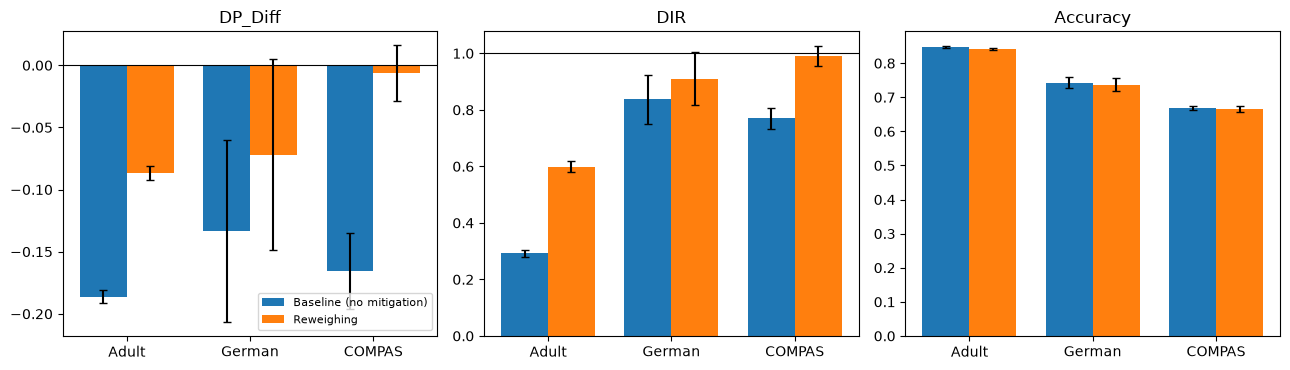

In [11]:
settings = ["Baseline (no mitigation)", "Reweighing"]
stats = two.groupby(["Dataset", "Setting"])[["DP_Diff", "DIR", "Accuracy"]].agg(["mean", "std"])
names = list(data)
x = np.arange(len(names))
width = 0.38

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, metric in zip(axes, ["DP_Diff", "DIR", "Accuracy"]):
    for j, setting in enumerate(settings):
        means = [stats.loc[(n, setting), (metric, "mean")] for n in names]
        stds = [stats.loc[(n, setting), (metric, "std")] for n in names]
        ax.bar(x + (j - 0.5) * width, means, width, yerr=stds, capsize=3, label=setting)
    ax.set_xticks(x)
    ax.set_xticklabels(names)
    ax.set_title(metric)
axes[0].axhline(0, color="k", lw=0.8)    # DP_Diff = 0 is fair
axes[1].axhline(1, color="k", lw=0.8)    # DIR = 1 is fair
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/comparison.png", dpi=150)
plt.show()